# Exploring fear and physiology during VR spider exposure

This notebook looks at the dataset used throughout this project: Krumnikl et al. (2026),
*"Do Virtual Spiders Feel Real? Dissociation Between Subjective and Physiological Fear
During Virtual Reality Exposure"* (Zenodo, DOI [10.5281/zenodo.20796399](https://doi.org/10.5281/zenodo.20796399), CC-BY-4.0).

It covers the dataset shape, how self-reported fear and physiology change across exposure
levels, whether they agree with each other, and a short summary of the modeling result.

Run `python -m vr_fear_prediction.download_data`, `python -m vr_fear_prediction.data`, and
`python -m vr_fear_prediction.modeling` before running this notebook.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

from vr_fear_prediction.data import build_long_dataset, load_raw_summary, validate_raw_summary
from vr_fear_prediction import evaluation, visualization

sns.set_theme(style="whitegrid", context="notebook")
PROJECT_ROOT = Path.cwd().parent


## 1. Dataset overview

In [2]:
raw_df = load_raw_summary(PROJECT_ROOT / "data" / "raw" / "summary.csv")
report = validate_raw_summary(raw_df)
print(f"{report.n_participants} participants, valid: {report.is_valid}")

long_df, _ = build_long_dataset(PROJECT_ROOT / "data" / "raw" / "summary.csv")
print(f"{len(long_df)} observations ({report.n_participants} participants x 10 exposure levels)")
long_df.head()


28 participants, valid: True
280 observations (28 participants x 10 exposure levels)


,participant_id,level,suds,PPG_HR,PPG_HR_delta_baseline,PULSE_HR,PULSE_HR_delta_baseline,RESP_RATE,RESP_RATE_delta_baseline,EDA_MEAN,...,education,vr_experience,ar_experience,vr_ar_frequency,SPQ_total,SPQ_A (Avoidance Behavior),SPQ_F (Fear/Disgust Reaction),SPQ_I (Cognitive Beliefs),questionnaire_stai_x2,questionnaire_stai_x1_before
0,P04,0,0,84.5249,0.0000,86.0777,0.0000,22.2838,0.0000,2545.1787,...,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
1,P04,1,0,86.3181,1.7932,83.9341,-2.1436,22.3236,0.0398,2586.4561,...,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
2,P04,2,0,88.3298,3.8049,86.5557,0.4780,20.0749,-2.2089,2542.2143,...,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
3,P04,3,0,79.4281,-5.0968,87.3120,1.2343,23.8284,1.5446,2541.4094,...,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
4,P04,4,0,80.2005,-4.3244,83.2331,-2.8446,20.0501,-2.2337,2507.6643,...,vysokoškolské,yes,no,monthly,2,2,0,0,58,41


Each participant contributes one row per exposure level (0 = neutral baseline, 1-9 =
escalating spider tasks). The dataset authors only computed physiological features for
levels 0-9, so those are the ones used here -- see `data/README.md` for the full column
documentation and exclusions.


## 2. Fear and physiology across exposure levels

In [3]:
print(long_df["suds"].describe())


count    280.000000
mean       3.425000
std        2.769797
min        0.000000
25%        1.000000
50%        3.000000
75%        6.000000
max       10.000000
Name: suds, dtype: float64


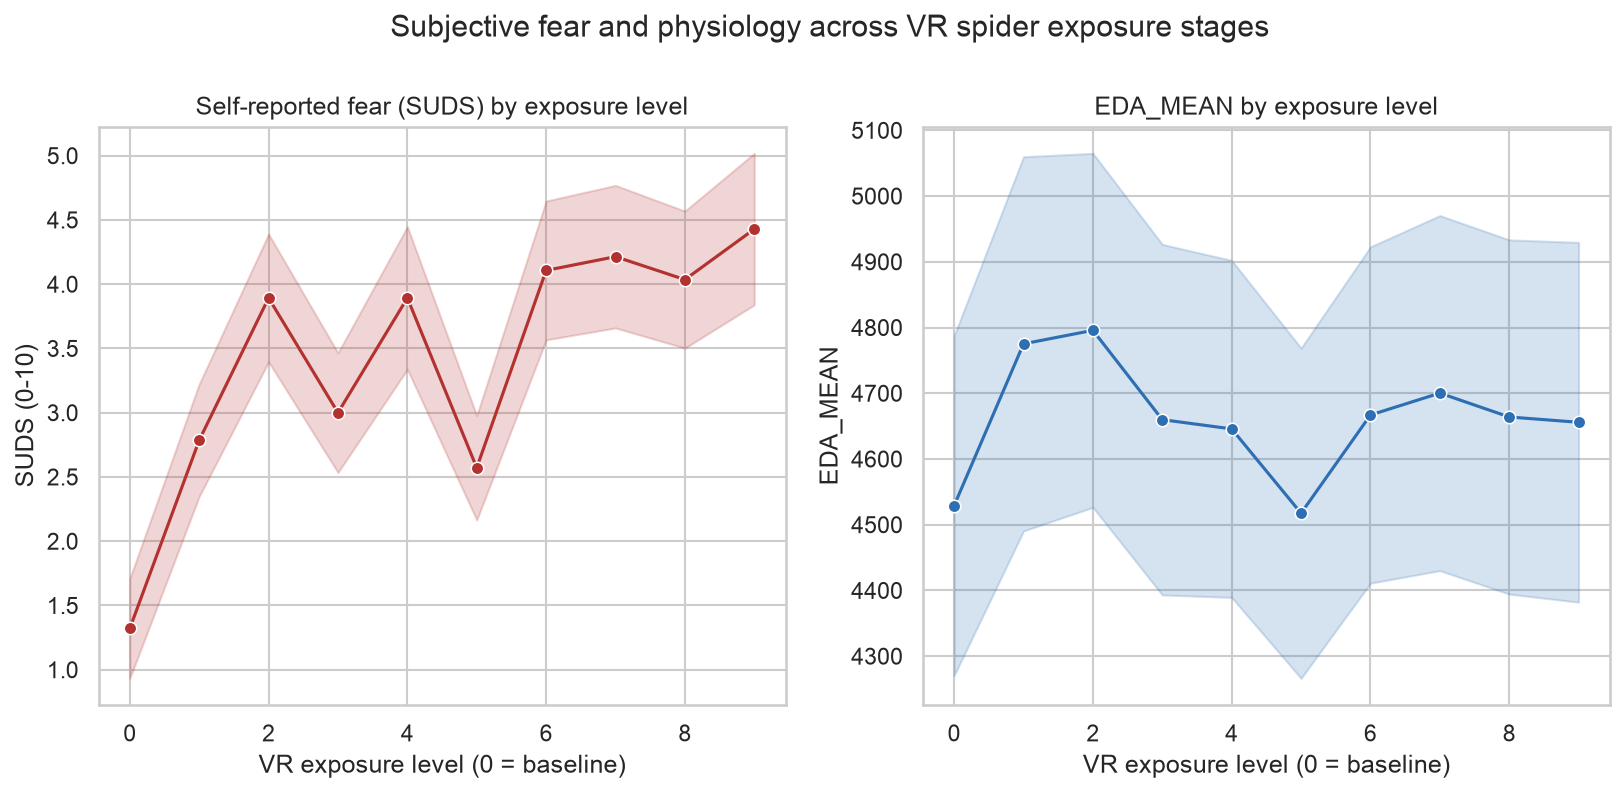

In [4]:
fig_path = visualization.plot_suds_and_physio_by_level(long_df)
display(Image(filename=str(fig_path)))


Self-reported fear rises with exposure level, with most participants at or near 0 at
baseline. EDA follows a broadly similar but noisier pattern.


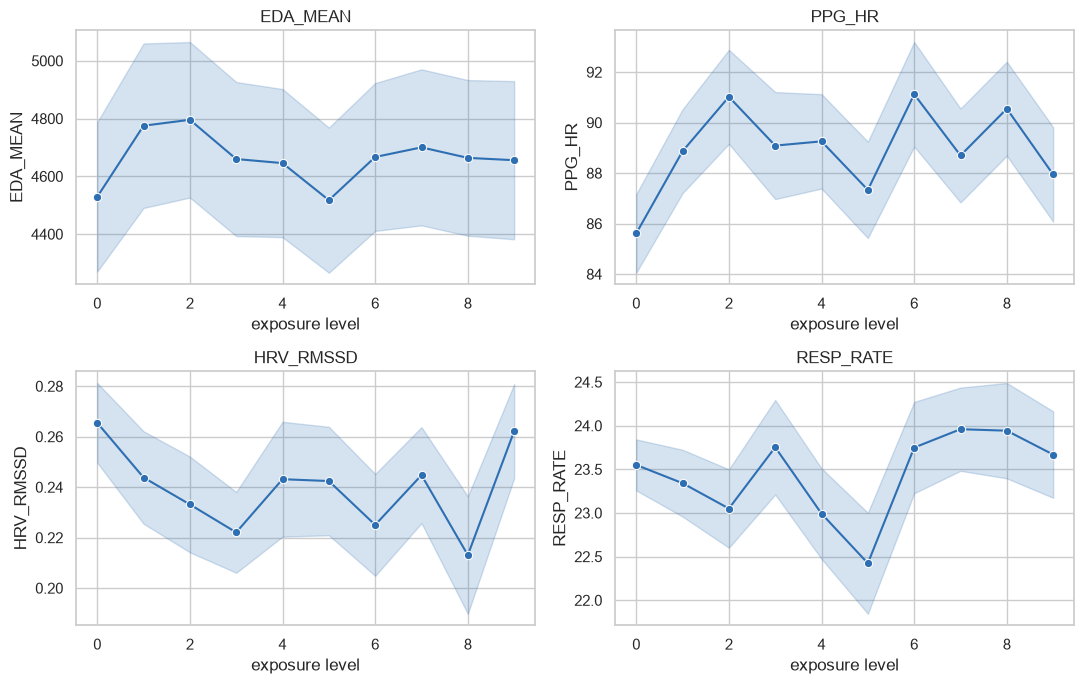

In [5]:
physio_cols = ["EDA_MEAN", "PPG_HR", "HRV_RMSSD", "RESP_RATE"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, physio_cols):
    sns.lineplot(data=long_df, x="level", y=col, errorbar="se", marker="o", ax=ax, color="#2e6fb3")
    ax.set_title(col)
    ax.set_xlabel("exposure level")
fig.tight_layout()
plt.show()


## 3. Subjective vs. physiological dissociation

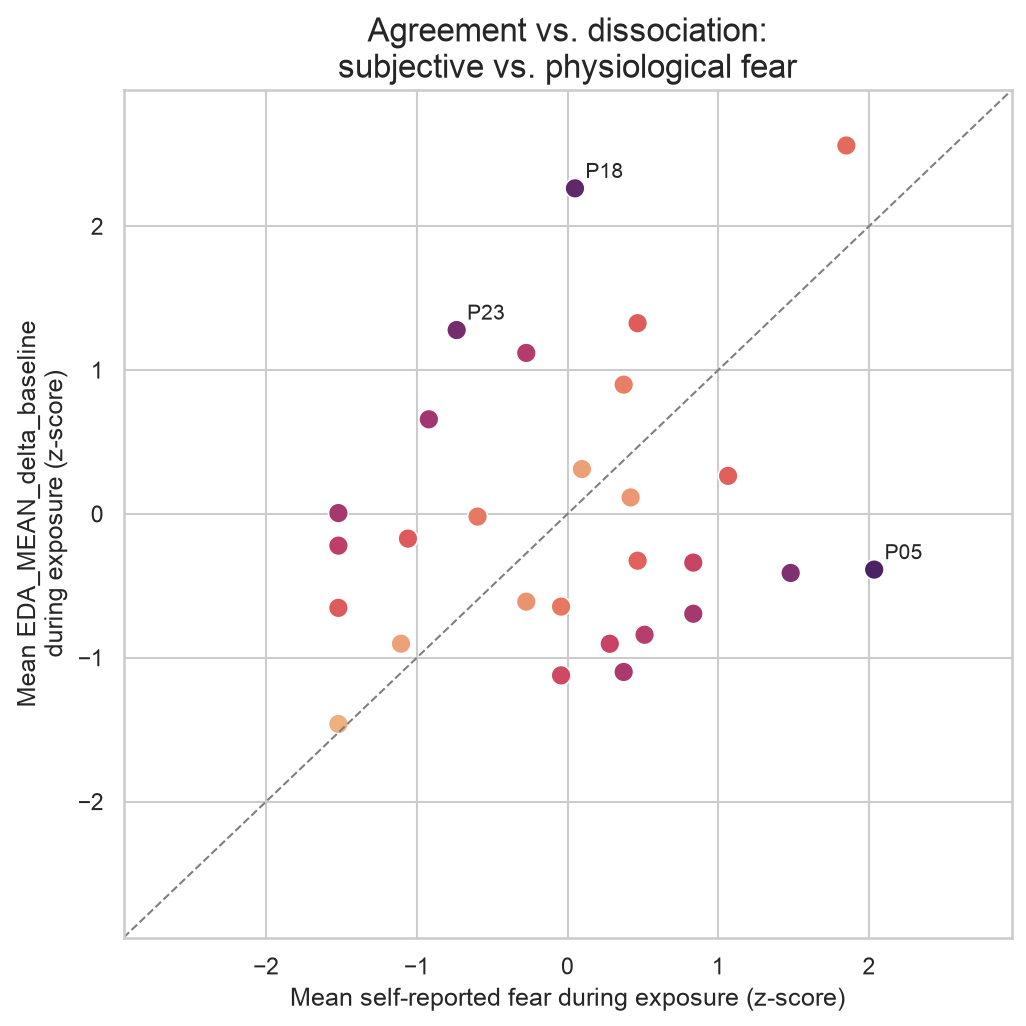

In [6]:
fig_path = visualization.plot_dissociation(long_df)
display(Image(filename=str(fig_path)))


In [7]:
rm_corr = evaluation.repeated_measures_correlation(long_df, "participant_id", "EDA_MEAN_delta_baseline", "suds")
print("within-participant correlation (EDA change from baseline vs. SUDS):", rm_corr)


within-participant correlation (EDA change from baseline vs. SUDS): {'r': 0.19364796381861168, 'p_value': 0.0011270114562450697, 'n_observations': 280}


The correlation is positive but modest, and some participants sit far from the
diagonal in the figure above -- they report high fear with little physiological change, or
the reverse. Subjective and physiological fear track each other loosely, not tightly.


## 4. Modeling result

In [8]:
metrics = json.loads((PROJECT_ROOT / "reports" / "metrics.json").read_text())

rows = []
for feature_set, models in metrics["feature_sets"].items():
    best = models["best_model"]
    rows.append({
        "feature_set": feature_set,
        "best_model": best,
        "cv_MAE": round(models[best]["cv"]["MAE_mean"], 2),
        "test_MAE": round(models[best]["held_out_test"]["MAE"], 2),
    })
pd.DataFrame(rows)


,feature_set,best_model,cv_MAE,test_MAE
0,context_only,ridge,1.82,1.31
1,physiology_only,dummy_mean,2.37,2.56
2,combined,ridge,2.09,0.89


Evidence that physiology adds predictive value beyond context is inconclusive. The combined model performs better on one held-out participant split, but worse under participant-aware cross-validation. With only 28 participants, this difference is unstable and may depend strongly on which participants are held out.

combined beat context-only in 54% of 50 repeated participant-level holdout splits


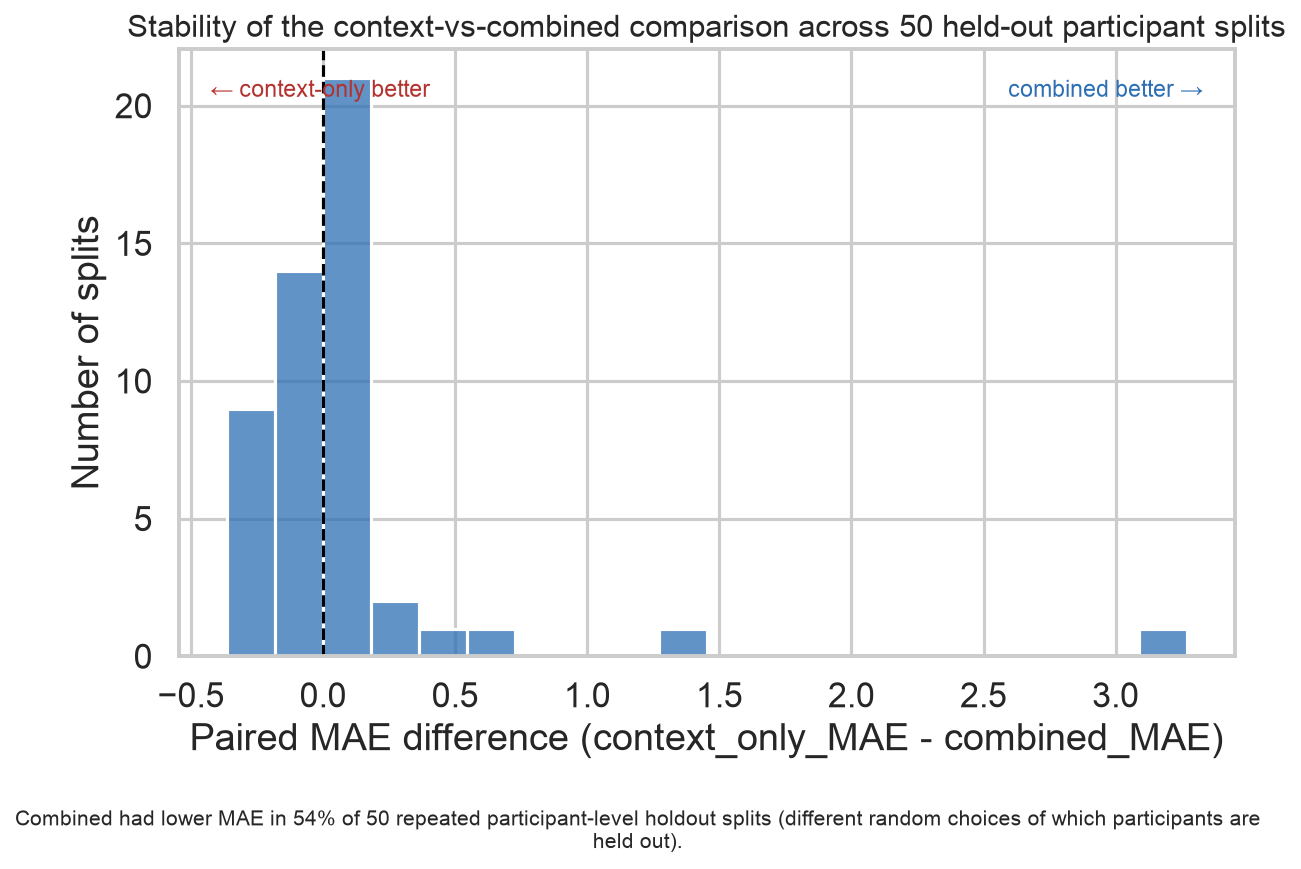

In [9]:
pv = metrics["physiology_value_assessment"]
print(pv["summary"])
print()
frac = pv["repeated_participant_holdout"]["paired_difference_context_minus_combined"]["fraction_splits_combined_better"]
print(f"combined beat context-only in {frac:.0%} of {pv['repeated_participant_holdout']['n_splits']} repeated participant-level holdout splits")

fig_path = PROJECT_ROOT / "reports" / "figures" / "paired_mae_difference_repeated_holdout.png"
display(Image(filename=str(fig_path)))


A baseline-exclusion sensitivity check (repeating everything on exposure levels 1-9
only) gives the same picture -- see `reports/metrics.json` and the README for the full
numbers.
